# What makes a TV show rate well on IMDb?

Exploring every rated TV series and episode in the public IMDb datasets to answer a few questions:

1. **Categories:** how do anime, western animation, live-action dramas and comedies compare?
2. **Over time:** has that changed by the decade a show premiered?
3. **Season by season:** do shows get better or worse as they go on?
4. **Pilot vs finale:** do shows stick the landing?
5. **Inside a season:** where do the best episodes sit?
6. **Deep dives:** episode-by-episode views of some well-known shows

Data comes from `src/prepare.py` (run it first). Anime is identified using Wikidata, because IMDb itself
only tags anime as *Animation*, the same as *The Simpsons*.

In [1]:
import sys, warnings
sys.path.insert(0, "../src")
warnings.filterwarnings("ignore")
import pandas as pd
import analysis as A

A.set_style()
pd.set_option("display.max_columns", 20)
series, episodes = A.load()
print(f"{len(series):,} rated series and mini-series, {len(episodes):,} rated episodes")
series.head()

142,244 rated series and mini-series, 877,187 rated episodes


,tconst,titleType,primaryTitle,originalTitle,startYear,endYear,genres,averageRating,numVotes,is_anime,category,rated_episodes,seasons,episode_votes
0,tt0035803,tvSeries,The German Weekly Review,Die Deutsche Wochenschau,1940,1945,"Documentary,News",8.1,75,False,Documentary,0,0,0
1,tt0038276,tvSeries,You Are an Artist,You Are an Artist,1946,1955,Talk-Show,6.1,18,False,Reality / talk,0,0,0
2,tt0039120,tvSeries,Americana,Americana,1947,1949,"Family,Game-Show",3.1,23,False,Reality / talk,0,0,0
3,tt0039122,tvSeries,The Borden Show,The Borden Show,1947,<NA>,"Comedy,Music",3.2,17,False,Live-action comedy,0,0,0
4,tt0039123,tvSeries,Kraft Mystery Theatre,Kraft Television Theatre,1947,1958,Drama,7.8,256,False,Live-action drama,14,7,597


In [2]:
series["category"].value_counts()

category
Live-action drama     46287
Live-action comedy    23308
Reality / talk        21890
Other                 19928
Documentary           17292
Western animation      9802
Anime                  3737
Name: count, dtype: int64

## 1. How does each kind of show rate?

Only series with 1,000+ votes are counted, so a show rated 10/10 by its creator's friends doesn't skew things.

In [3]:
A.category_summary(series)

,count,25%,median,75%,mean
category,,,,,
Reality / talk,896.0,5.8,6.9,7.70,6.64
Western animation,1256.0,6.5,7.2,7.80,7.01
Anime,1015.0,6.9,7.3,7.80,7.35
Live-action drama,6662.0,6.7,7.3,7.80,7.21
Live-action comedy,1963.0,6.7,7.4,7.90,7.25
Other,257.0,6.6,7.4,8.00,7.15
Documentary,958.0,7.0,7.6,8.28,7.52


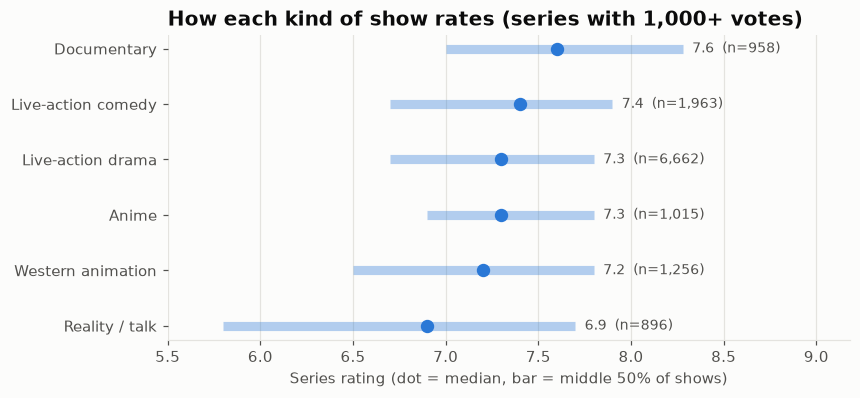

In [4]:
fig = A.plot_category_ratings(series)
A.save(fig, "01_category_ratings.png")

Documentaries and comedies sit highest. Reality/talk shows are clearly lowest. **Anime edges out western animation**
(median 7.3 vs 7.2), and the middle 50% of anime sits higher. Part of that is selection: the anime that gets
1,000+ votes on an English-language site is the anime that got popular abroad.

## 2. Has that changed over time?

category,Anime,Live-action comedy,Live-action drama,Western animation
decade,,,,
1960,NaN,7.40,7.5,7.20
1970,7.90,7.65,7.6,7.20
1980,7.75,7.35,7.6,7.20
1990,7.70,7.40,7.4,7.20
2000,7.60,7.60,7.5,7.10
2010,7.30,7.30,7.4,7.20
2020,7.10,7.15,7.2,7.15


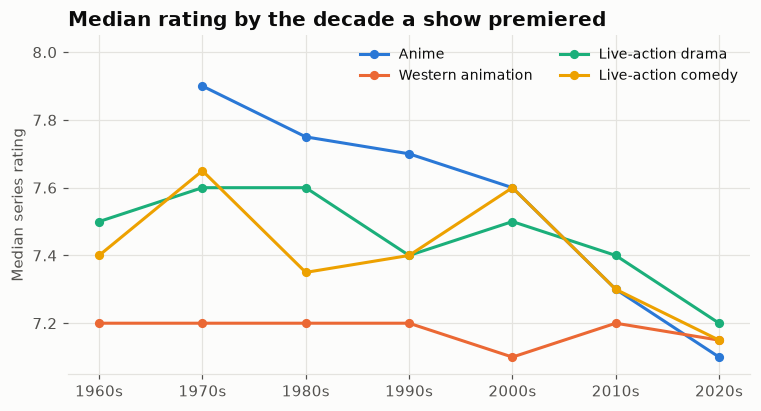

In [5]:
fig = A.plot_by_decade(series)
A.save(fig, "02_by_decade.png")
A.by_decade(series).pivot(index="decade", columns="category", values="median")

Older shows rate higher, especially anime and dramas. That's survivorship bias: people only go back and rate
the 1970s-80s shows that are still worth remembering. Anime from the 1970s-90s rates highest of any group, while
western animation is remarkably flat at about 7.2 in every decade.

## 3. Do shows get better or worse season by season?

For every show with 5,000+ votes and at least 3 seasons (each with 4+ rated episodes), I take the average
episode rating per season and subtract season 1.

In [6]:
ss = A.season_table(series, episodes)
print(f"{ss['parentTconst'].nunique():,} shows")
A.trajectory(ss).pivot(index="seasonNumber", columns="category", values="median").round(2)

1,837 shows


category,Anime,Live-action comedy,Live-action drama,Western animation
seasonNumber,,,,
1,0.00,0.00,0.00,0.00
2,0.09,0.10,0.08,0.04
3,0.18,0.09,0.03,0.04
4,0.09,0.04,0.05,-0.02
5,-0.06,0.01,0.03,-0.07
6,NaN,0.00,-0.00,-0.09
7,NaN,-0.11,-0.03,-0.19
8,NaN,-0.15,-0.04,-0.15


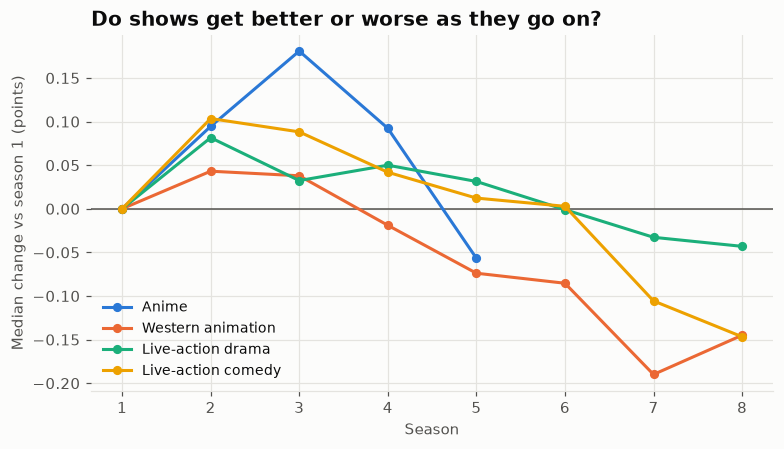

In [7]:
fig = A.plot_trajectory(ss)
A.save(fig, "03_season_trajectory.png")

In [8]:
best = ss.loc[ss.groupby("parentTconst")["rating"].idxmax()]
last = ss.groupby("parentTconst")["seasonNumber"].max()
print(f"Best season is season 1:     {(best['seasonNumber'] == 1).mean():.0%}")
print(f"Best season is the last one: {(best['seasonNumber'].values == last.loc[best['parentTconst']].values).mean():.0%}")
print(f"Best season is in between:   {1 - (best['seasonNumber'] == 1).mean() - (best['seasonNumber'].values == last.loc[best['parentTconst']].values).mean():.0%}")

Best season is season 1:     21%
Best season is the last one: 22%
Best season is in between:   57%


The typical show **improves in seasons 2-3**. Anime climbs the most early on, probably because each season
adapts a manga arc and the big arcs come later. After that, western animation is the first to fade (below
season 1 from season 4), and comedies drop off sharply from season 7. Live-action dramas hold closest to
their season-1 level, partly because dramas that slip tend to get cancelled. Most shows (57%) peak in a middle
season, not the first or the last.

## 4. Pilot vs finale

For finished series (has an end year, 10,000+ votes, 10+ rated episodes), compare the first and last episode.

In [9]:
pf = A.pilot_finale(series, episodes)
print(f"{len(pf):,} finished shows")
print(f"Finale rated higher than pilot:       {(pf['finale'] > pf['pilot']).mean():.0%}")
print(f"Finale rated higher than show average: {(pf['finale'] > pf['show_avg']).mean():.0%}")
pf.groupby("category")[["finale_minus_pilot", "finale_minus_avg"]].median()

1,794 finished shows
Finale rated higher than pilot:       69%
Finale rated higher than show average: 70%


,finale_minus_pilot,finale_minus_avg
category,,
Anime,0.70,0.580
Documentary,0.05,0.010
Live-action comedy,0.40,0.260
Live-action drama,0.40,0.290
Other,0.50,0.250
Reality / talk,0.10,0.290
Western animation,0.50,0.385


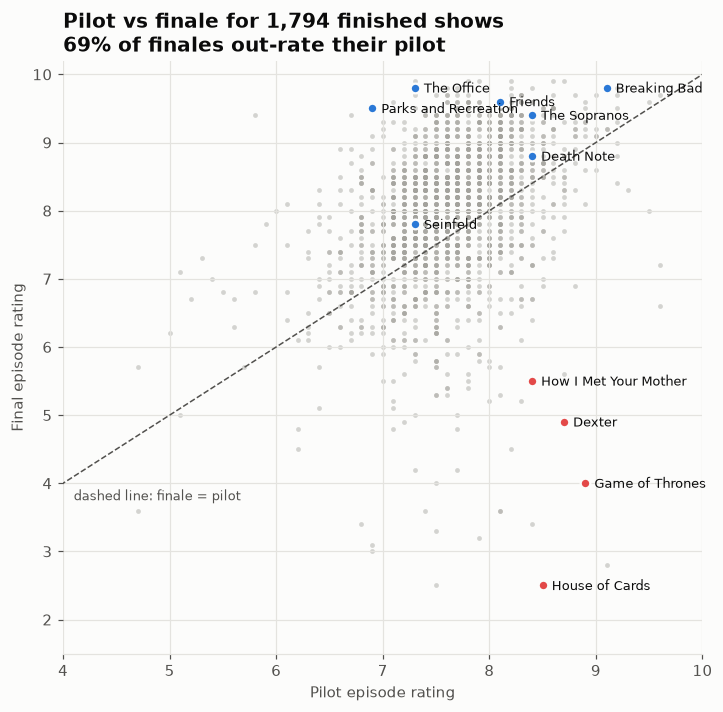

In [10]:
fig = A.plot_pilot_finale(pf)
A.save(fig, "04_pilot_vs_finale.png")

### The worst landings: biggest drop from the show's average to its finale (200k+ votes)

In [11]:
cols = ["primaryTitle", "startYear", "endYear", "pilot", "finale", "show_avg", "finale_minus_avg"]
pf[pf["numVotes"] >= 200_000].nsmallest(10, "finale_minus_avg")[cols]

,primaryTitle,startYear,endYear,pilot,finale,show_avg,finale_minus_avg
parentTconst,,,,,,,
tt1856010,House of Cards,2013,2018,8.5,2.5,7.95,-5.45
tt0944947,Game of Thrones,2011,2019,8.9,4.0,8.74,-4.74
tt0369179,Two and a Half Men,2003,2015,8.1,3.6,7.28,-3.68
tt0773262,Dexter,2006,2013,8.7,4.9,8.45,-3.55
tt1312171,The Umbrella Academy,2019,2024,7.7,4.8,7.67,-2.87
tt1190634,The Boys,2019,2026,8.7,5.6,8.18,-2.58
tt0460649,How I Met Your Mother,2005,2014,8.4,5.5,8.00,-2.50
tt0844441,True Blood,2008,2014,7.8,5.4,7.89,-2.49
tt7335184,You,2018,2025,8.1,5.3,7.78,-2.48


### The best landings

In [12]:
pf[pf["numVotes"] >= 200_000].nlargest(10, "finale_minus_avg")[cols]

,primaryTitle,startYear,endYear,pilot,finale,show_avg,finale_minus_avg
parentTconst,,,,,,,
tt0988824,Naruto: Shippuden,2007,2017,8.2,9.3,7.30,2.00
tt0386676,The Office,2005,2013,7.3,9.8,8.07,1.73
tt0898266,The Big Bang Theory,2007,2019,8.1,9.5,7.77,1.73
tt4955642,The Good Place,2016,2020,7.8,9.6,8.07,1.53
tt1266020,Parks and Recreation,2009,2015,6.9,9.5,8.05,1.45
tt0397442,Gossip Girl,2007,2012,7.5,9.0,7.60,1.40
tt2467372,Brooklyn Nine-Nine,2013,2021,7.7,9.4,8.00,1.40
tt0165598,That '70s Show,1998,2006,7.9,8.9,7.54,1.36
tt9335498,Demon Slayer: Kimetsu no Yaiba,2019,2024,8.3,9.7,8.35,1.35


**About 70% of finales beat the pilot.** That's partly real (finales get the budget and the payoff) and partly
selection again: the people still rating the last episode are the fans who stayed. That makes the
disasters stand out even more. *Game of Thrones* averaged 8.7 per episode and ended on a 4.0.
Sitcoms (*The Office*, *Parks and Recreation*, *Friends*) dominate the best-landing list. Their finales
are reunion-style send-offs built for long-time viewers.

## 5. Where in a season are the best episodes?

Each episode is compared to its own season's average, so a great show and a bad show are on the same scale.

In [13]:
pos = A.episode_position(series, episodes)
pos

,mean,count,share_above_avg
position,,,
Premiere,-0.024,14313,0.437
Middle episodes,-0.019,210129,0.466
Penultimate,0.095,14072,0.619
Finale,0.205,14522,0.698


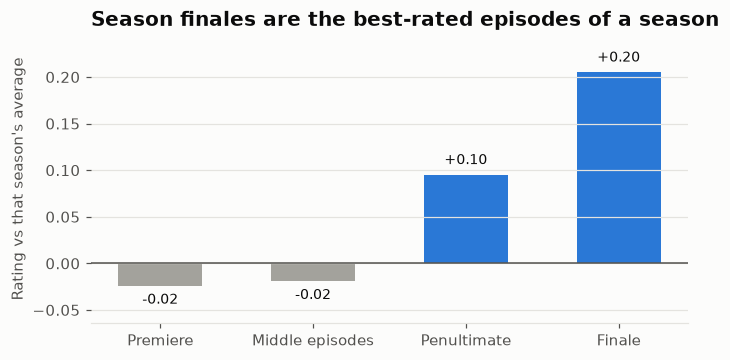

In [14]:
fig = A.plot_episode_position(pos)
A.save(fig, "05_episode_position.png")

Season finales beat their season's average by about **0.2 points** and the penultimate episode by about 0.1.
Premieres and middle episodes sit just below average. Writers save the big moments for the end of the
season, and ratings follow.

## 6. Deep dives

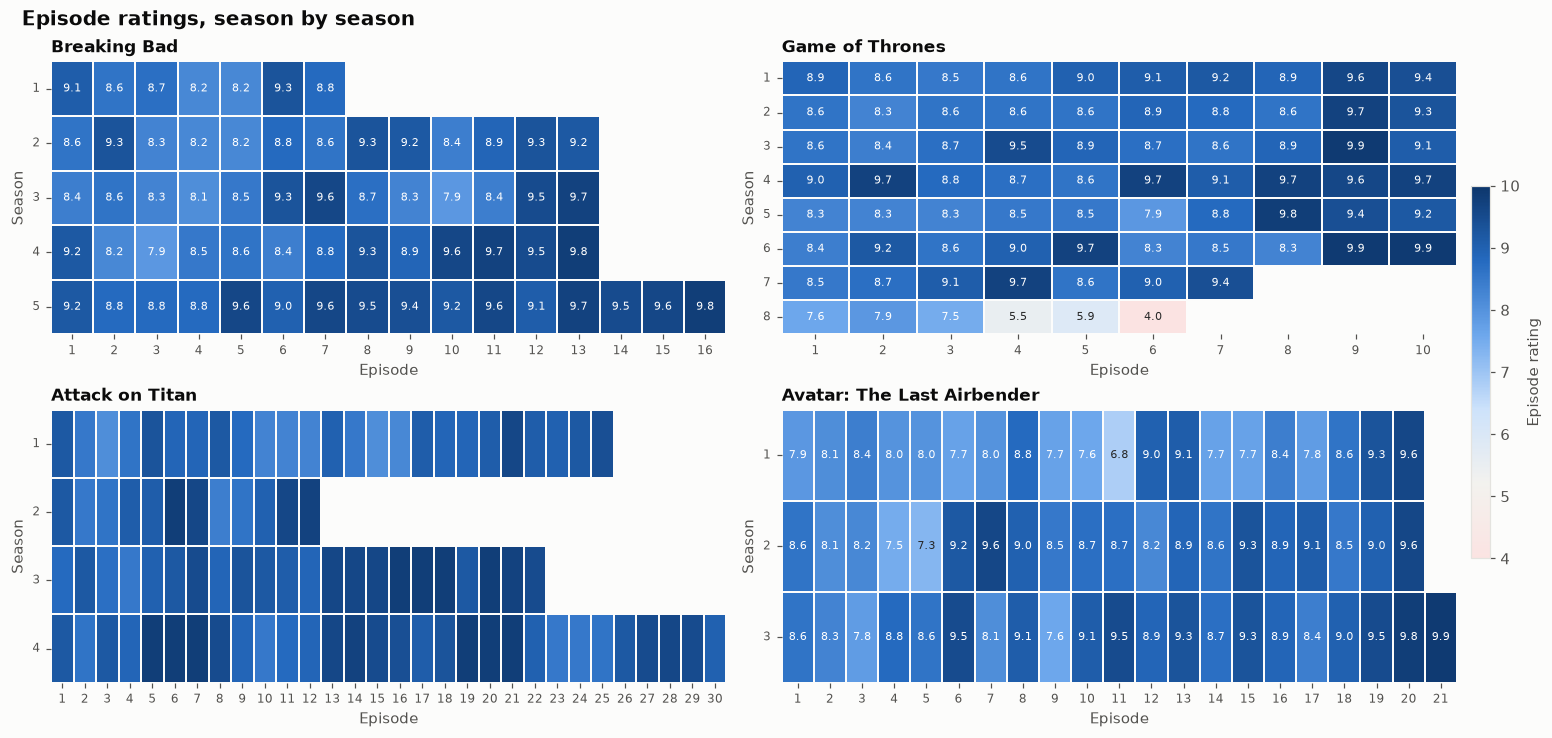

In [15]:
fig = A.plot_show_heatmaps(series, episodes,
    ["Breaking Bad", "Game of Thrones", "Attack on Titan", "Avatar: The Last Airbender"])
A.save(fig, "06_show_heatmaps.png")

- **Breaking Bad** gets steadily better, and its best run is in the final season (*Ozymandias*).
- **Game of Thrones** sits mostly between 8.3 and 9.9 for seven seasons, then collapses in season 8.
- **Attack on Titan** rates consistently high, with its strongest runs in the back halves of seasons 3 and 4.
- **Avatar** builds each season toward a multi-part finale.

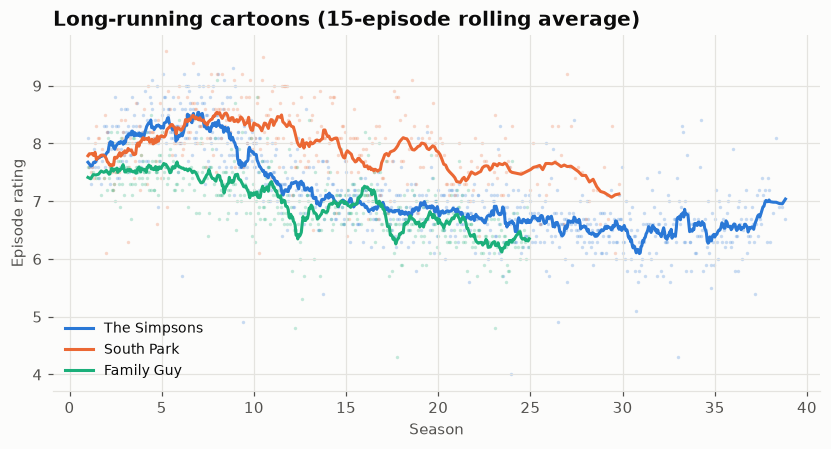

In [16]:
fig = A.plot_long_runners(series, episodes, ["The Simpsons", "South Park", "Family Guy"])
A.save(fig, "07_long_running_cartoons.png")

*The Simpsons'* "golden age" (seasons 3-8) shows up clearly, followed by a long decline it never recovered
from. *South Park* has held its level far better over a similar number of seasons.

## Limitations and next steps

- **Ratings are self-selected.** People choose what to watch and what to rate, so most comparisons here are
  "how fans rate" rather than "how good it is".
- **No studio data.** The IMDb datasets don't include production companies. Joining with TMDB's API
  (`production_companies`) would allow studio comparisons (e.g. MAPPA vs Wit Studio vs Toei).
- **Episode votes vary a lot.** A weighted version (by `numVotes`) would reduce noise from thinly rated episodes.
- **Anime list** relies on Wikidata coverage, which is very good for popular shows and thinner for obscure ones.